# Electricity Consumption Prediction Using Regression

This project explores the relationship between temperature and electricity consumption using regression techniques. A Linear Regression model is used as a baseline, followed by Polynomial Regression and boosting-based regressors. The models are evaluated on training and testing data to compare their performance.

##  Import Libraries

Import the Python libraries required for data handling, visualization, preprocessing, model training, and evaluation.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

##  Load the Dataset

Load the electricity and weather dataset into a pandas DataFrame. The target variable for this project is `electricity_kwh`.

In [3]:
df = pd.read_csv("electricity_weather.csv")
df.head()

,electricity_kwh,temperature,humidity,wind_speed,solar_radiation,peak_hours,day_type
0,12.37,18.1,40.1,19.4,294.6,4,Weekday
1,43.84,38.3,46.7,2.6,717.4,5,Weekday
2,22.53,30.6,40.6,2.5,672.0,7,Weekday
3,14.50,26.0,35.3,9.4,487.2,6,Weekend
4,18.52,10.5,37.2,13.2,157.7,6,Weekday


##  Initial Dataset Inspection

Check the dataset dimensions, column information, summary statistics, missing values, and duplicate records before preprocessing.

In [4]:
df.shape

(600, 7)

In [5]:
df.describe()

,electricity_kwh,humidity,wind_speed,solar_radiation,peak_hours
count,600.00000,600.000000,600.000000,600.000000,600.000000
mean,22.30745,59.716667,13.370000,455.815667,6.000000
std,9.01873,17.457409,6.687139,212.903110,1.432977
min,9.42000,30.300000,2.100000,50.000000,4.000000
25%,15.49750,43.975000,7.400000,264.325000,5.000000
50%,19.68500,60.000000,13.350000,481.050000,6.000000
75%,26.04000,74.900000,18.825000,626.500000,7.000000
max,49.72000,89.900000,25.000000,859.900000,8.000000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   electricity_kwh  600 non-null    float64
 1   temperature      600 non-null    object 
 2   humidity         600 non-null    float64
 3   wind_speed       600 non-null    float64
 4   solar_radiation  600 non-null    float64
 5   peak_hours       600 non-null    int64  
 6   day_type         600 non-null    object 
dtypes: float64(4), int64(1), object(2)
memory usage: 32.9+ KB


In [7]:
df.isnull().sum()

electricity_kwh    0
temperature        0
humidity           0
wind_speed         0
solar_radiation    0
peak_hours         0
day_type           0
dtype: int64

In [8]:
df.duplicated().sum()

0

In [9]:
df.head(10)

,electricity_kwh,temperature,humidity,wind_speed,solar_radiation,peak_hours,day_type
0,12.37,18.1,40.1,19.4,294.6,4,Weekday
1,43.84,38.3,46.7,2.6,717.4,5,Weekday
2,22.53,30.6,40.6,2.5,672.0,7,Weekday
3,14.50,26.0,35.3,9.4,487.2,6,Weekend
4,18.52,10.5,37.2,13.2,157.7,6,Weekday
5,19.25,10.5,57.6,19.7,236.8,6,Weekday
6,22.80,7.0,42.4,17.7,199.3,7,Weekend
7,31.18,35.3,51.9,12.3,741.9,8,Weekday
8,15.54,26.0,60.2,8.3,569.8,8,Weekday
9,20.69,29.8,71.4,24.9,558.2,5,Weekday


##  Check the Main Feature and Target

Inspect the temperature and electricity consumption columns. This project initially uses temperature as the single input feature so the relationship and fitted regression curves are easy to interpret.

In [10]:

print(df[["temperature", "electricity_kwh"]].describe())

print(df[["temperature", "electricity_kwh"]].dtypes)

       electricity_kwh
count        600.00000
mean          22.30745
std            9.01873
min            9.42000
25%           15.49750
50%           19.68500
75%           26.04000
max           49.72000
temperature         object
electricity_kwh    float64
dtype: object


### Preparing the Temperature Feature

The `temperature` column is stored as text (`object`) rather than a numeric data type. Convert it to numeric so it can be used in calculations, plotting, and regression. This conversion does not create a curved relationship; the shape of the relationship must be examined from the data.

### Convert Temperature to a Numeric Data Type

The temperature values are stored as text. Convert them to numeric values so they can be used in statistical calculations and regression models.

In [11]:
df["temperature"] = pd.to_numeric(df["temperature"], errors="coerce")

The conversion uses `errors="coerce"`, so any values that cannot be interpreted as numbers become missing values (`NaN`). These rows are removed before model training.

### Remove Rows with Missing Required Values

Remove rows where temperature or electricity consumption is missing, because both columns are required for this modelling task.

In [12]:
df = df.dropna(subset=["temperature", "electricity_kwh"])

## Exploratory Data Analysis

These plots help inspect the target distribution, the temperature feature, and the relationship between temperature and electricity consumption. The correlation heatmap provides additional context for the numerical columns.

### Electricity Consumption Distribution

This histogram shows how electricity consumption values are distributed across the observations.

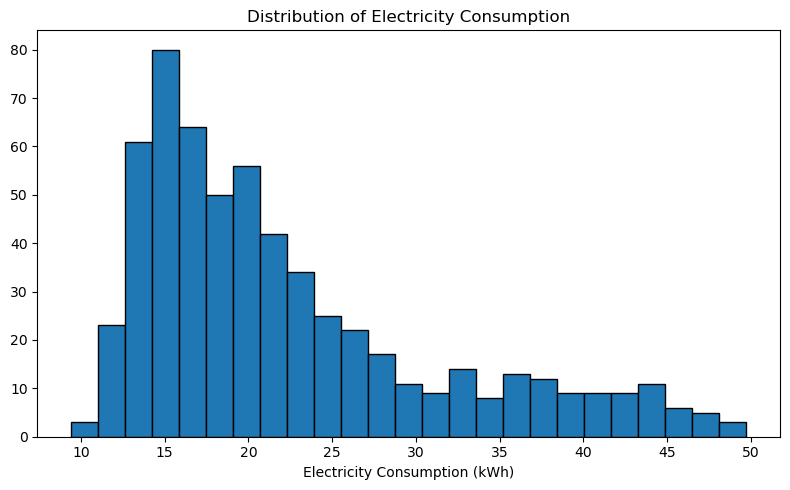

In [13]:
plt.figure(figsize=(8, 5))
plt.hist(df["electricity_kwh"], bins=25, edgecolor="black")
plt.xlabel("Electricity Consumption (kWh)")
plt.title("Distribution of Electricity Consumption")
plt.tight_layout()
plt.show()

### Temperature Distribution

This histogram helps inspect the range and distribution of temperature values.

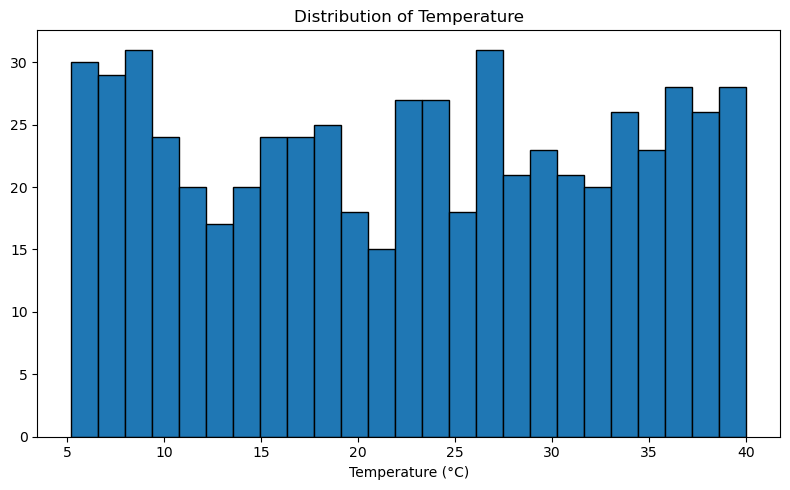

In [14]:
plt.figure(figsize=(8, 5))
plt.hist(df["temperature"], bins=25, edgecolor="black")
plt.xlabel("Temperature (°C)")
plt.title("Distribution of Temperature")
plt.tight_layout()
plt.show()

### Temperature vs. Electricity Consumption

The scatter plot helps identify whether the relationship appears approximately linear or curved. This visual inspection helps motivate testing polynomial features.

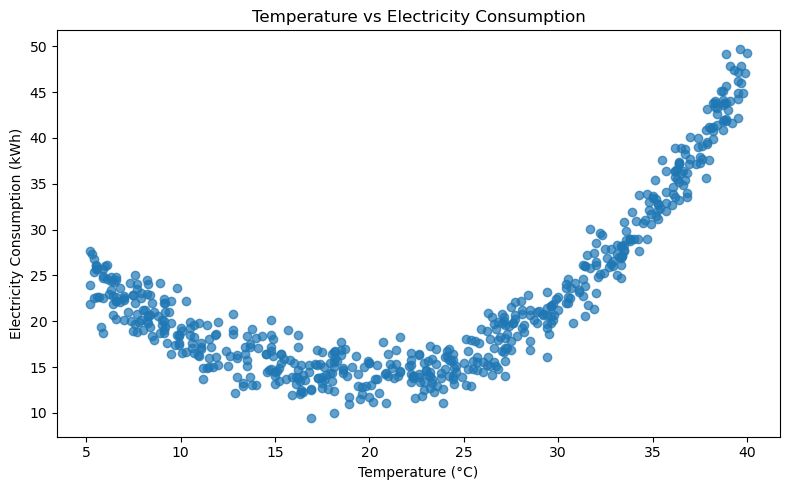

In [15]:
plt.figure(figsize=(8, 5))
plt.scatter(df["temperature"], df["electricity_kwh"], alpha=0.7)
plt.xlabel("Temperature (°C)")
plt.ylabel("Electricity Consumption (kWh)")
plt.title("Temperature vs Electricity Consumption")
plt.tight_layout()
plt.show()

### Correlation Between Numerical Features

The heatmap summarizes pairwise linear correlations among numerical columns. Correlation can help describe associations, but it does not establish causation or by itself determine which regression model is best.

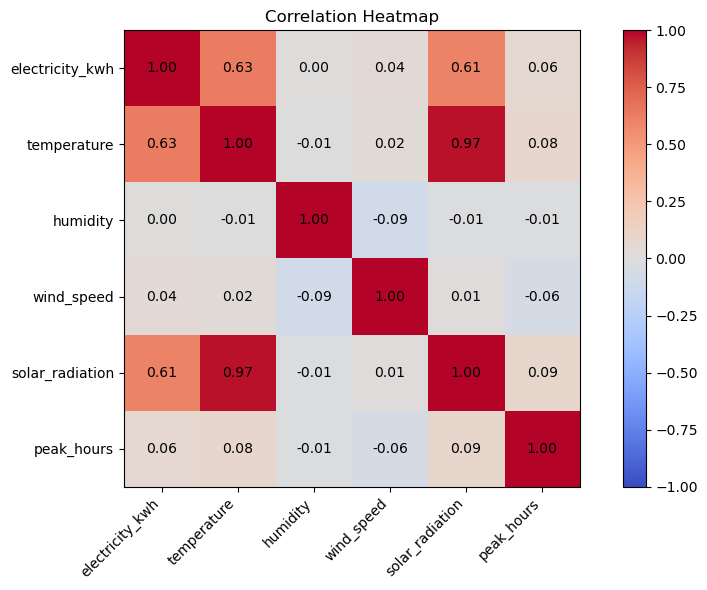

In [16]:
plt.figure(figsize=(9, 6))
corr = df.select_dtypes(include="number").corr()
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)
for row in range(len(corr.columns)):
    for col in range(len(corr.columns)):
        plt.text(col, row, f"{corr.iloc[row, col]:.2f}", ha="center", va="center")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 5. Select the Input Feature and Target

`temperature` is used as the input feature (`X`), while `electricity_kwh` is the value to predict (`y`). Other available columns are explored in EDA but are not included in this single-feature model comparison.

In [17]:
X = df[["temperature"]]
y = df["electricity_kwh"]

### Visualize the Selected Feature and Target

Plot the selected input feature against the target before splitting the data.

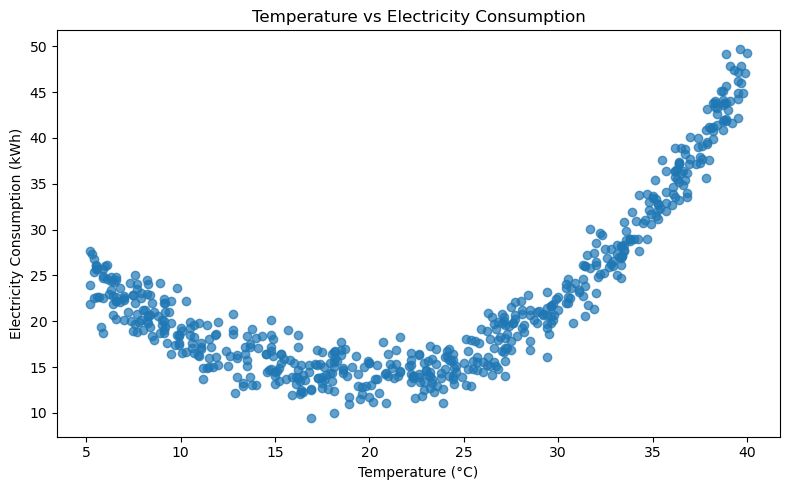

In [18]:
plt.figure(figsize=(8, 5))
plt.scatter(X["temperature"], y, alpha=0.7)
plt.xlabel("Temperature (°C)")
plt.ylabel("Electricity Consumption (kWh)")
plt.title("Temperature vs Electricity Consumption")
plt.tight_layout()
plt.show()

## Linear Regression Baseline

First, a simple Linear Regression model is trained using temperature as the single input feature. Its performance provides a baseline for comparison with polynomial regression and the boosting models.

### Split the Dataset and Train the Baseline Model

Split the observations into training and testing sets. Train Linear Regression on the training data and use the held-out test data to assess how well it predicts unseen observations.

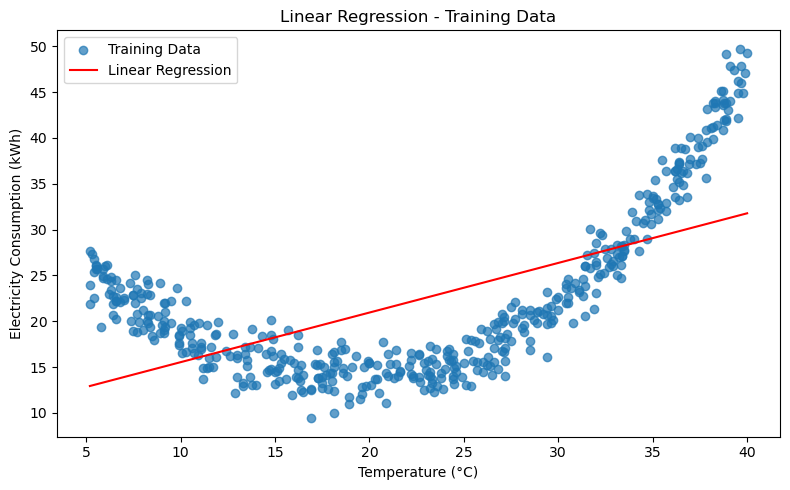

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_train)
y_pred1 = model.predict(X_test)

# Plot the training data and a smooth, sorted regression line
X_curve = pd.DataFrame({"temperature": np.linspace(X["temperature"].min(), X["temperature"].max(), 300)})
y_curve = model.predict(X_curve)

plt.figure(figsize=(8, 5))
plt.scatter(X_train["temperature"], y_train, alpha=0.7, label="Training Data")
plt.plot(X_curve["temperature"], y_curve, color="red", label="Linear Regression")
plt.xlabel("Temperature (°C)")
plt.ylabel("Electricity Consumption (kWh)")
plt.title("Linear Regression - Training Data")
plt.legend()
plt.tight_layout()
plt.show()

#### Linear Regression: Training Performance

Evaluate the baseline model on the data used to fit it.

Evaluation on training data

In [20]:

# Evaluation metrics
print("MAE:", mean_absolute_error(y_train, y_pred))
print("MSE:", mean_squared_error(y_train, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_train, y_pred)))
print("R2 Score:", r2_score(y_train, y_pred))

MAE: 6.034267822211097
MSE: 49.64082844350034
RMSE: 7.045624773112768
R2 Score: 0.39174013963838705


#### Linear Regression: Test Predictions

Visualize the baseline model's predictions against the held-out test observations.

#### Testing Data

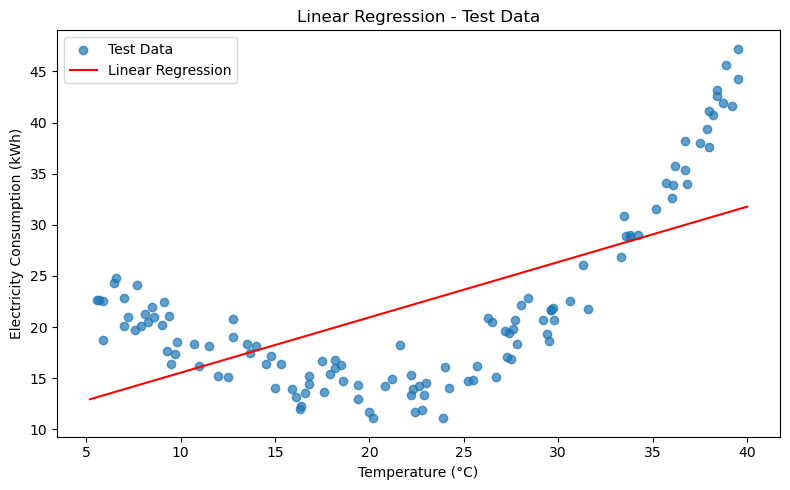

In [21]:
plt.figure(figsize=(8, 5))
plt.scatter(X_test["temperature"], y_test, alpha=0.7, label="Test Data")
plt.plot(X_curve["temperature"], y_curve, color="red", label="Linear Regression")
plt.xlabel("Temperature (°C)")
plt.ylabel("Electricity Consumption (kWh)")
plt.title("Linear Regression - Test Data")
plt.legend()
plt.tight_layout()
plt.show()

#### Linear Regression: Testing Performance

Calculate evaluation metrics on the test set. These results are more informative for estimating performance on unseen data than training metrics alone.

Evaluation on testing data

In [22]:
# Evaluation metrics
print("MAE:", mean_absolute_error(y_test, y_pred1))
print("MSE:", mean_squared_error(y_test, y_pred1))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred1)))
print("R2 Score:", r2_score(y_test, y_pred1))

MAE: 5.904426378544981
MSE: 45.94282978540312
RMSE: 6.778114028651563
R2 Score: 0.4086253339162045


## 6. Polynomial Regression – Degree 2

Polynomial Regression adds a squared version of the input feature, allowing the model to fit a curved relationship while remaining a linear model in its learned coefficients. Degree 2 adds the squared term.

### Polynomial Regression -- Degree 2

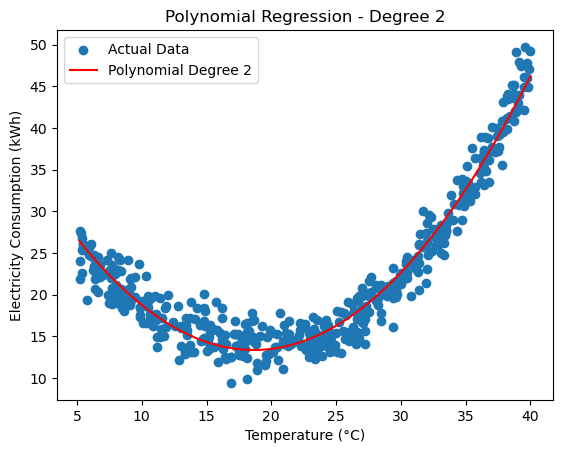

In [23]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model_poly2 = LinearRegression()

model_poly2.fit(X_train_poly, y_train)

y_pred_poly = model_poly2.predict(X_train_poly)
y_pred_poly2 = model_poly2.predict(X_test_poly)

# Plot the data points and polynomial curve
X_curve = pd.DataFrame({"temperature": np.linspace(X.min().iloc[0], X.max().iloc[0], 300)})

X_curve_poly = poly.transform(X_curve)

y_curve = model_poly2.predict(X_curve_poly)

plt.scatter(X_train["temperature"], y_train, label="Actual Data")

plt.plot(
    X_curve["temperature"], y_curve,
    color="red", label="Polynomial Degree 2"
)

plt.xlabel("Temperature (°C)")
plt.ylabel("Electricity Consumption (kWh)")
plt.title("Polynomial Regression - Degree 2")
plt.legend()

plt.show()

#### Degree 2: Training Performance

Evaluate the degree-2 polynomial model on its training data.

In [24]:
# Evaluation metrics
print("MAE:", mean_absolute_error(y_train, y_pred_poly))
print("MSE:", mean_squared_error(y_train, y_pred_poly))
print("RMSE:", np.sqrt(mean_squared_error(y_train, y_pred_poly)))
print("R2 Score:", r2_score(y_train, y_pred_poly))

MAE: 1.5369958964006973
MSE: 3.759477229550238
RMSE: 1.9389371391435664
R2 Score: 0.9539343083832377


#### Degree 2: Testing Performance

Evaluate the degree-2 polynomial model on the held-out test data.

In [25]:
# Evaluation metrics
print("MAE:", mean_absolute_error(y_test, y_pred_poly2))
print("MSE:", mean_squared_error(y_test, y_pred_poly2))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_poly2)))
print("R2 Score:", r2_score(y_test, y_pred_poly2))

# Save Degree 2 predictions for the final model comparison
y_pred_poly2_test_saved = y_pred_poly2.copy()
y_pred_poly2_train_saved = y_pred_poly.copy()

MAE: 1.6489330466142929
MSE: 4.043765692275604
RMSE: 2.0109116570042564
R2 Score: 0.9479487746584043


## 7. Polynomial Regression – Degree 3

Degree 3 adds a cubic term to the polynomial features. This gives the model more flexibility, but a higher degree can also increase the risk of overfitting. Compare training and testing metrics rather than relying only on training performance.

### Polynomial Regression Degree 3

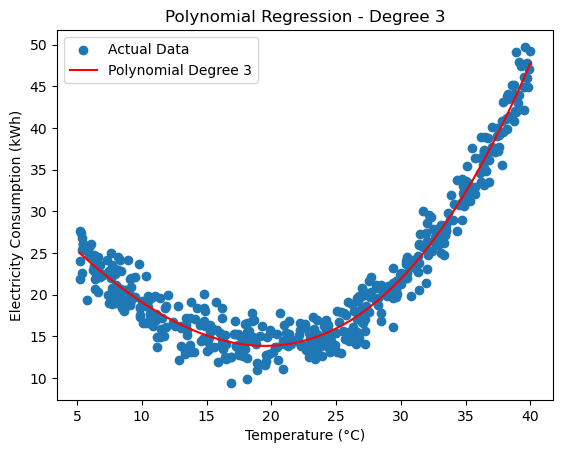

In [26]:
from sklearn.preprocessing import PolynomialFeatures

poly = PolynomialFeatures(degree=3)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model_poly2 = LinearRegression()

model_poly2.fit(X_train_poly, y_train)

y_pred_poly = model_poly2.predict(X_train_poly)
y_pred_poly2 = model_poly2.predict(X_test_poly)

# Plot the data points and polynomial curve
X_curve = pd.DataFrame({"temperature": np.linspace(X.min().iloc[0], X.max().iloc[0], 300)})

X_curve_poly = poly.transform(X_curve)

y_curve = model_poly2.predict(X_curve_poly)

plt.scatter(X_train["temperature"], y_train, label="Actual Data")

plt.plot(
    X_curve["temperature"], y_curve,
    color="red", label="Polynomial Degree 3"
)

plt.xlabel("Temperature (°C)")
plt.ylabel("Electricity Consumption (kWh)")
plt.title("Polynomial Regression - Degree 3")
plt.legend()

plt.show()

#### Degree 3: Training Performance

Evaluate the degree-3 polynomial model on its training data.

In [27]:
# Evaluation metrics
print("MAE:", mean_absolute_error(y_train, y_pred_poly))
print("MSE:", mean_squared_error(y_train, y_pred_poly))
print("RMSE:", np.sqrt(mean_squared_error(y_train, y_pred_poly)))
print("R2 Score:", r2_score(y_train, y_pred_poly))

MAE: 1.4874080283899096
MSE: 3.375561962654354
RMSE: 1.8372702475831784
R2 Score: 0.9586385055925685


#### Degree 3: Testing Performance

Evaluate the degree-3 polynomial model on the held-out test data.

In [28]:
# Evaluation metrics
print("MAE:", mean_absolute_error(y_test, y_pred_poly2))
print("MSE:", mean_squared_error(y_test, y_pred_poly2))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_poly2)))
print("R2 Score:", r2_score(y_test, y_pred_poly2))

# Save Degree 3 predictions for the final model comparison
y_pred_poly3_test_saved = y_pred_poly2.copy()
y_pred_poly3_train_saved = y_pred_poly.copy()

MAE: 1.5431689101859527
MSE: 3.4975161739633833
RMSE: 1.870164745139685
R2 Score: 0.9549800813497688


## Boosting Regression Algorithms

The following ensemble regressors are added for comparison with Linear Regression and Polynomial Regression. All three use the same temperature feature and the existing training/testing split.

### Import the Boosting Regressors

Import AdaBoost, Gradient Boosting, and XGBoost regressors for comparison. XGBoost is an additional package and may need to be installed separately.

In [29]:
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

### AdaBoost Regression

In [30]:
model_ada = AdaBoostRegressor(random_state=42)
model_ada.fit(X_train, y_train)

y_pred_ada_train = model_ada.predict(X_train)
y_pred_ada_test = model_ada.predict(X_test)

print("Training R2:", r2_score(y_train, y_pred_ada_train))
print("Testing R2:", r2_score(y_test, y_pred_ada_test))
print("Testing MAE:", mean_absolute_error(y_test, y_pred_ada_test))
print("Testing RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_ada_test)))

Training R2: 0.95449346146717
Testing R2: 0.9395059095076824
Testing MAE: 1.7243104358628965
Testing RMSE: 2.1678737597057447


### Gradient Boosting Regression

In [31]:
model_gb = GradientBoostingRegressor(random_state=42)
model_gb.fit(X_train, y_train)

y_pred_gb_train = model_gb.predict(X_train)
y_pred_gb_test = model_gb.predict(X_test)

print("Training R2:", r2_score(y_train, y_pred_gb_train))
print("Testing R2:", r2_score(y_test, y_pred_gb_test))
print("Testing MAE:", mean_absolute_error(y_test, y_pred_gb_test))
print("Testing RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_gb_test)))

Training R2: 0.971589468941184
Testing R2: 0.9476937655009626
Testing MAE: 1.6383800645440223
Testing RMSE: 2.015831563690455


### XGBoost Regression

In [32]:
model_xgb = XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=3, random_state=42, objective="reg:squarederror")
model_xgb.fit(X_train, y_train)

y_pred_xgb_train = model_xgb.predict(X_train)
y_pred_xgb_test = model_xgb.predict(X_test)

print("Training R2:", r2_score(y_train, y_pred_xgb_train))
print("Testing R2:", r2_score(y_test, y_pred_xgb_test))
print("Testing MAE:", mean_absolute_error(y_test, y_pred_xgb_test))
print("Testing RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_xgb_test)))

Training R2: 0.9654676083157463
Testing R2: 0.9505980166268575
Testing MAE: 1.5939064633051554
Testing RMSE: 1.9590688778798628


## Model Performance Comparison

The table compares the models using the same train/test split. Test-set metrics are especially important because they estimate performance on data that was not used for fitting.

### Compare Model Performance

Compare the training and testing R² scores and the test RMSE for each model. A higher test R² and a lower test RMSE generally indicate better predictive performance on this held-out split. Also compare training and testing scores to look for signs of overfitting.

In [33]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression (Degree 2)", "Polynomial Regression (Degree 3)", "AdaBoost Regressor", "Gradient Boosting Regressor", "XGBoost Regressor"],
    "Train R2": [
        r2_score(y_train, y_pred),
        r2_score(y_train, y_pred_poly2_train_saved),
        r2_score(y_train, y_pred_poly3_train_saved),
        r2_score(y_train, y_pred_ada_train),
        r2_score(y_train, y_pred_gb_train),
        r2_score(y_train, y_pred_xgb_train)
    ],
    "Test R2": [
        r2_score(y_test, y_pred1),
        r2_score(y_test, y_pred_poly2_test_saved),
        r2_score(y_test, y_pred_poly3_test_saved),
        r2_score(y_test, y_pred_ada_test),
        r2_score(y_test, y_pred_gb_test),
        r2_score(y_test, y_pred_xgb_test)
    ],
    "Test RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred1)),
        np.sqrt(mean_squared_error(y_test, y_pred_poly2_test_saved)),
        np.sqrt(mean_squared_error(y_test, y_pred_poly3_test_saved)),
        np.sqrt(mean_squared_error(y_test, y_pred_ada_test)),
        np.sqrt(mean_squared_error(y_test, y_pred_gb_test)),
        np.sqrt(mean_squared_error(y_test, y_pred_xgb_test))
    ]
})

results

,Model,Train R2,Test R2,Test RMSE
0,Linear Regression,0.391740,0.408625,6.778114
1,Polynomial Regression (Degree 2),0.953934,0.947949,2.010912
2,Polynomial Regression (Degree 3),0.958639,0.954980,1.870165
3,AdaBoost Regressor,0.954493,0.939506,2.167874
4,Gradient Boosting Regressor,0.971589,0.947694,2.015832
5,XGBoost Regressor,0.965468,0.950598,1.959069


### Test R² Score Visualization

This chart makes it easier to compare the models' test-set R² scores. Use it together with the numerical metrics rather than as the only basis for choosing a model.

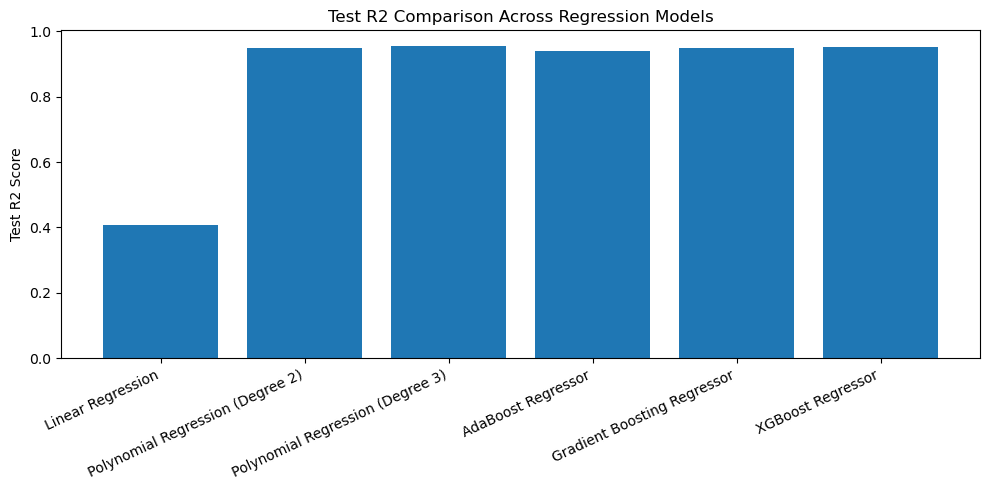

In [34]:
plt.figure(figsize=(10, 5))
plt.bar(results["Model"], results["Test R2"])
plt.xticks(rotation=25, ha="right")
plt.ylabel("Test R2 Score")
plt.title("Test R2 Comparison Across Regression Models")
plt.tight_layout()
plt.show()

##  Conclusion

This project compares a simple Linear Regression baseline with Polynomial Regression (degrees 2 and 3) and three boosting-based regression algorithms: AdaBoost, Gradient Boosting, and XGBoost. The comparison uses the same selected input feature and train/test split.

The final model should be selected using held-out test performance, including R² and RMSE, while checking the gap between training and testing results. The findings describe the supplied dataset and should not be generalized to all electricity consumers without further validation on independently sourced data.